# Proyecto Final IA 1 (Grupo C2 2026-2): Predicción Temprana de Riesgo de Accidentes Cerebrovasculares (ACV) (Grupo 3)

## Planteamiento del Problema y Motivación
* **Relevancia clínica:** Los accidentes cerebrovasculares (ACV) constituyen una de las principales causas de mortalidad y discapacidad permanente a nivel mundial. Un sistema de triaje preventivo basado en variables clínicas y demográficas rutinarias permite identificar pacientes de alto riesgo antes de un evento crítico.
* **Desafíos técnicos del problema:**
  1. **Desbalance severo de clases:** Apenas el $4.87\%$ de los registros corresponden a eventos positivos de ACV, invalidando métricas tradicionales como el *Accuracy*.
  2. **Asimetría y valores faltantes:** Variables biomédicas clave como `avg_glucose_level` y `bmi` presentan fuertes sesgos positivos y datos incompletos que requieren imputación no paramétrica sin fuga de datos (*data leakage*).
  3. **Heterogeneidad de factores de riesgo:** Coexistencia de pacientes geriátricos metabólicos típicos y pacientes jóvenes con ACV atípicos.
* **Objetivos:** Construir y validar un flujo completo de ciencia de datos (EDA, Aprendizaje Supervisado y Aprendizaje No Supervisado) maximizando la **Sensibilidad (*Recall*)** y el **ROC-AUC** para minimizar los Falsos Negativos médicos.

---



# Parte 1: Análisis Exploratorio de Datos (`exploratory_data_analysis`)

## 1 Origen, Estructura y Definición del Problema
* **Fuente:** *Healthcare Dataset Stroke Data* ($5,110$ registros iniciales, $12$ columnas).
* **Tipo de problema:** Clasificación binaria supervisada.
* **Características ($X$):** $10$ variables predictoras tras descartar `id` (`age`, `gender`, `hypertension`, `heart_disease`, `ever_married`, `work_type`, `Residence_type`, `avg_glucose_level`, `bmi`, `smoking_status`).
* **Etiqueta objetivo ($y$):** Variable binaria `stroke` ($0 =$ No ACV, $1 =$ Sí ACV).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el archivo csv desde GitHub
url = 'https://raw.githubusercontent.com/CarrlosP/Proyect_IA/refs/heads/main/healthcare-dataset-stroke-data.csv'
df = pd.read_csv(url)


# Configuración visual general
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

print("Librerías cargadas correctamente.")

df.head()

Librerías cargadas correctamente.


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Inspección básica
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\n--- Información de Tipos de Datos y Nulos ---")
print(df.info())

# Limpieza inicial requerida
# 1. Eliminar ID por no aportar valor predictivo
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# 2. Filtrar el registro aislado de gender == 'Other'
df = df[df['gender'] != 'Other']

print(f"\nDimensiones tras limpieza inicial: {df.shape}")
df.head()

Dimensiones del dataset: 5110 filas y 12 columnas.

--- Información de Tipos de Datos y Nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
None

Dimensiones tras limpieza inicial: (5109, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


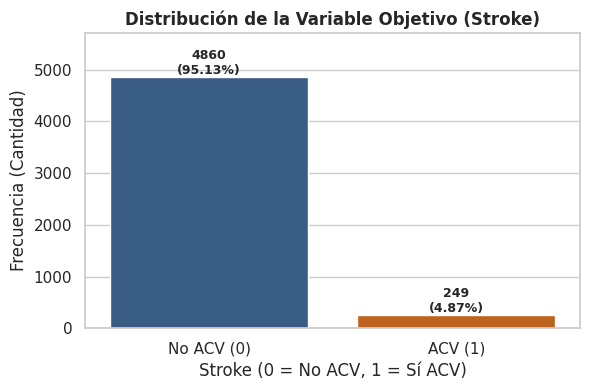

• No ACV (0): 4860 casos (95.13%)
• ACV (1): 249 casos (4.87%)


In [ ]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='stroke', hue='stroke', palette=['#2b5c8f', '#d95f02'], legend=False)
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{(height/total)*100:.2f}%'
    ax.annotate(f'{int(height)}\n({percentage})',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.title('Distribución de la Variable Objetivo (Stroke)', fontweight='bold')
plt.xlabel('Stroke (0 = No ACV, 1 = Sí ACV)')
plt.ylabel('Frecuencia (Cantidad)')
plt.xticks(ticks=[0, 1], labels=['No ACV (0)', 'ACV (1)'])
plt.ylim(0, ax.get_ylim()[1] * 1.12)  # espacio extra arriba para que no se corte el texto
plt.tight_layout()
plt.show()

# Reporte en texto para la presentación
conteo_target = df['stroke'].value_counts()
porcentaje_target = df['stroke'].value_counts(normalize=True) * 100

print(f"• No ACV (0): {conteo_target[0]} casos ({porcentaje_target[0]:.2f}%)")
print(f"• ACV (1): {conteo_target[1]} casos ({porcentaje_target[1]:.2f}%)")

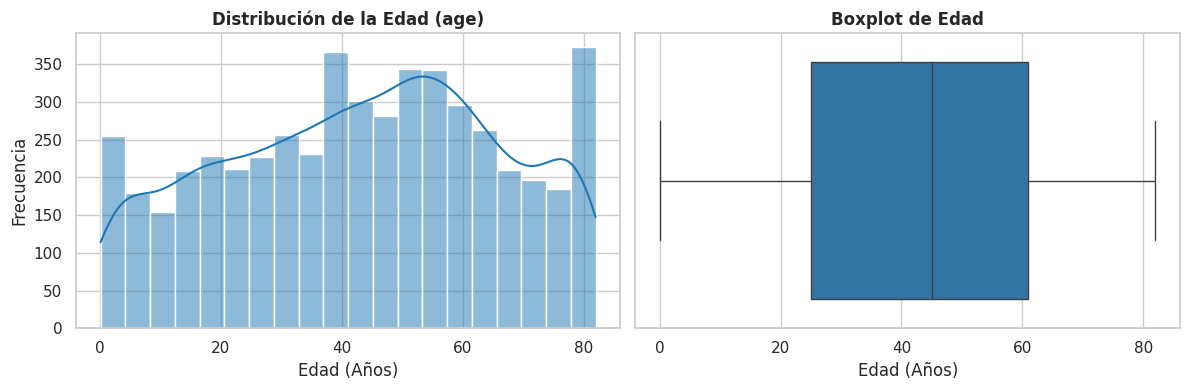

• 'La edad promedio de los pacientes es de 43.2 ± 22.6 años.'


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma con curva KDE
sns.histplot(data=df, x='age', kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title('Distribución de la Edad (age)', fontweight='bold')
axes[0].set_xlabel('Edad (Años)')
axes[0].set_ylabel('Frecuencia')

# Boxplot
sns.boxplot(data=df, x='age', color='#1f77b4', ax=axes[1])
axes[1].set_title('Boxplot de Edad', fontweight='bold')
axes[1].set_xlabel('Edad (Años)')

plt.tight_layout()
plt.show()

# Cálculo de estadísticas simétricas
media_age = df['age'].mean()
std_age = df['age'].std()


print(f"• 'La edad promedio de los pacientes es de {media_age:.1f} ± {std_age:.1f} años.'")

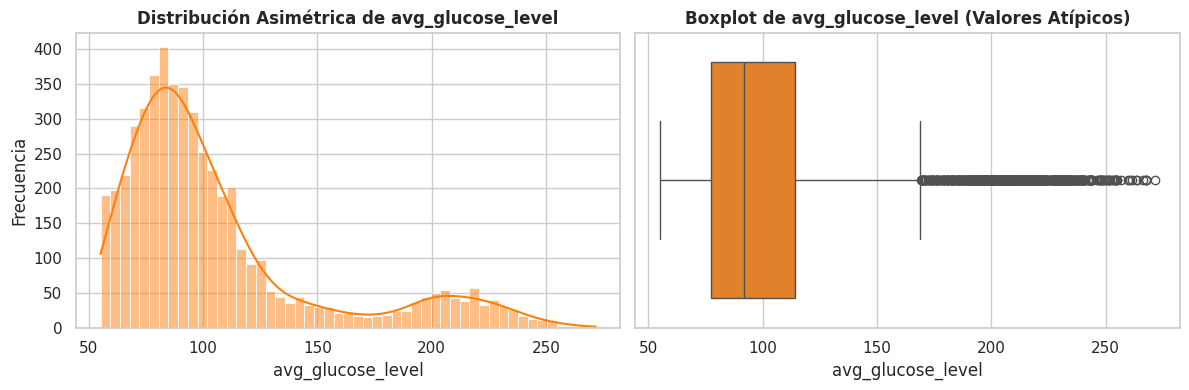

• Mediana: 91.88
• Rango Intercuartil (IQR): 36.85 (Q1: 77.24 - Q3: 114.09)
• Rango Total [Mín - Máx]: [55.12 - 271.74]



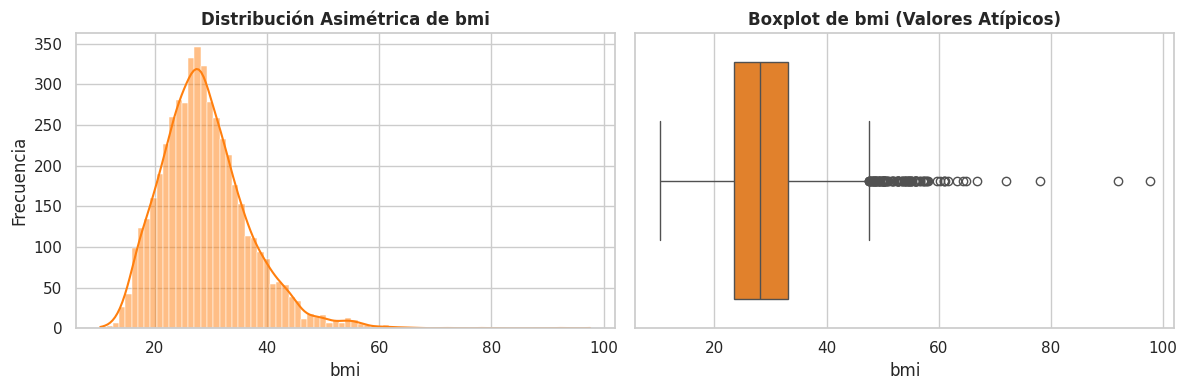

• Mediana: 28.10
• Rango Intercuartil (IQR): 9.60 (Q1: 23.50 - Q3: 33.10)
• Rango Total [Mín - Máx]: [10.30 - 97.60]



In [ ]:
vars_asimetricas = ['avg_glucose_level', 'bmi']

for var in vars_asimetricas:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histograma
    sns.histplot(data=df, x=var, kde=True, color='#ff7f0e', ax=axes[0])
    axes[0].set_title(f'Distribución Asimétrica de {var}', fontweight='bold')
    axes[0].set_ylabel('Frecuencia')

    # Boxplot para visualizar atípicos
    sns.boxplot(data=df, x=var, color='#ff7f0e', ax=axes[1])
    axes[1].set_title(f'Boxplot de {var} (Valores Atípicos)', fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Cálculo de estadísticas no paramétricas
    mediana = df[var].median()
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    iqr = q3 - q1


    print(f"• Mediana: {mediana:.2f}")
    print(f"• Rango Intercuartil (IQR): {iqr:.2f} (Q1: {q1:.2f} - Q3: {q3:.2f})")
    print(f"• Rango Total [Mín - Máx]: [{df[var].min():.2f} - {df[var].max():.2f}]\n")

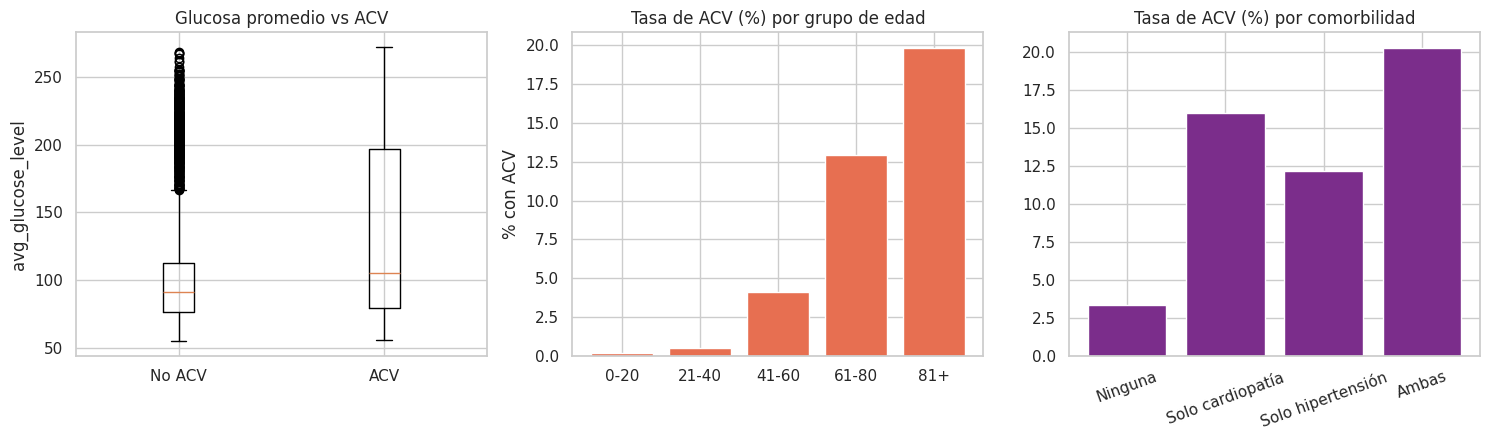

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt


df['bmi'] = pd.to_numeric(df['bmi'], errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# --- Panel 1: Glucosa promedio vs ACV (boxplot comparativo) ---
data0 = df[df.stroke == 0]['avg_glucose_level']
data1 = df[df.stroke == 1]['avg_glucose_level']
axes[0].boxplot([data0, data1], tick_labels=['No ACV', 'ACV'])
axes[0].set_title('Glucosa promedio vs ACV')
axes[0].set_ylabel('avg_glucose_level')

# --- Panel 2: Tasa de ACV (%) por grupo de edad ---
bins = [0, 20, 40, 60, 80, 100]
labels = ['0-20', '21-40', '41-60', '61-80', '81+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)
tasa = df.groupby('age_group', observed=True)['stroke'].mean() * 100
axes[1].bar(tasa.index.astype(str), tasa.values, color='#E76F51')
axes[1].set_title('Tasa de ACV (%) por grupo de edad')
axes[1].set_ylabel('% con ACV')

# --- Panel 3: Tasa de ACV (%) por comorbilidad combinada ---
df['riesgo_comb'] = df['hypertension'].astype(str) + "-" + df['heart_disease'].astype(str)
tasa2 = df.groupby('riesgo_comb')['stroke'].mean() * 100
labels2 = {'0-0': 'Ninguna', '1-0': 'Solo hipertensión', '0-1': 'Solo cardiopatía', '1-1': 'Ambas'}
tasa2.index = [labels2.get(x, x) for x in tasa2.index]
axes[2].bar(tasa2.index, tasa2.values, color='#7B2D8B')
axes[2].set_title('Tasa de ACV (%) por comorbilidad')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('cruces_variables.png', dpi=130)
plt.show()

/tmp/ipykernel_4227/1212001617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Blues_r', ax=axes[i])
/tmp/ipykernel_4227/1212001617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Blues_r', ax=axes[i])
/tmp/ipykernel_4227/1212001617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Blues_r', ax=axes[i])
/tmp/ipykernel_4227/1212001617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign th

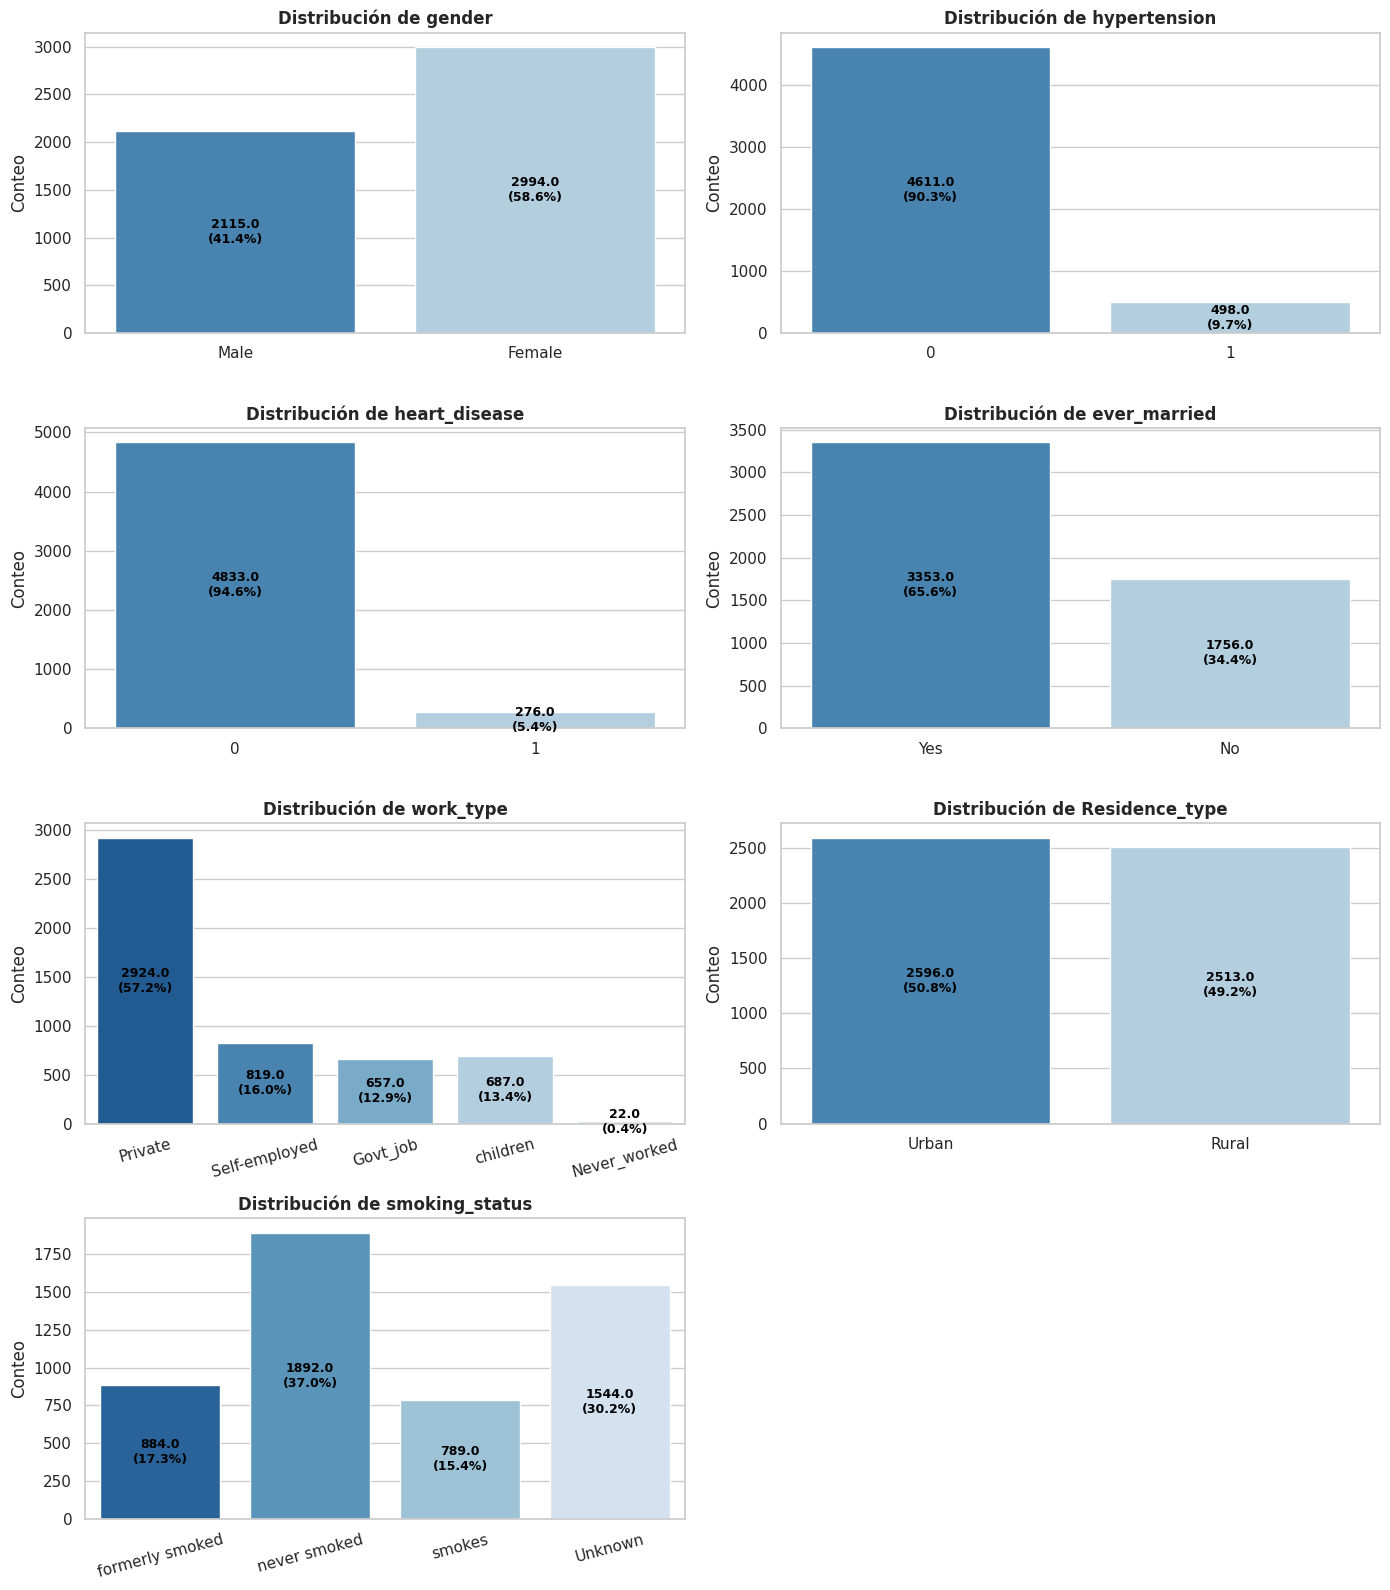


Variable: gender
        Frecuencia  Porcentaje (%)
gender                            
Female        2994            58.6
Male          2115            41.4

Variable: hypertension
              Frecuencia  Porcentaje (%)
hypertension                            
0                   4611           90.25
1                    498            9.75

Variable: heart_disease
               Frecuencia  Porcentaje (%)
heart_disease                            
0                    4833            94.6
1                     276             5.4

Variable: ever_married
              Frecuencia  Porcentaje (%)
ever_married                            
Yes                 3353           65.63
No                  1756           34.37

Variable: work_type
               Frecuencia  Porcentaje (%)
work_type                                
Private              2924           57.23
Self-employed         819           16.03
children              687           13.45
Govt_job              657           12.86


In [ ]:
cols_cat = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(cols_cat):
    sns.countplot(data=df, x=col, palette='Blues_r', ax=axes[i])
    axes[i].set_title(f'Distribución de {col}', fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Conteo')

    # Agregar porcentajes en las barras
    total_col = len(df[col].dropna())
    for p in axes[i].patches:
        height = p.get_height()
        porcentaje = (height / total_col) * 100
        axes[i].annotate(f'{height}\n({porcentaje:.1f}%)',
                         (p.get_x() + p.get_width() / 2., height / 2),
                         ha='center', va='center', color='black', fontsize=9, fontweight='bold')

    if col in ['work_type', 'smoking_status']:
        axes[i].tick_params(axis='x', rotation=15)

# Eliminar el subgráfico sobrente
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

# Imprimir resumen categórico impreso
for col in cols_cat:
    print(f"\nVariable: {col}")
    resumen = pd.DataFrame({
        'Frecuencia': df[col].value_counts(),
        'Porcentaje (%)': (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(resumen)

--- ANÁLISIS DE VALORES NULOS ---
     Valores Faltantes  Porcentaje (%)
bmi                201        3.934234


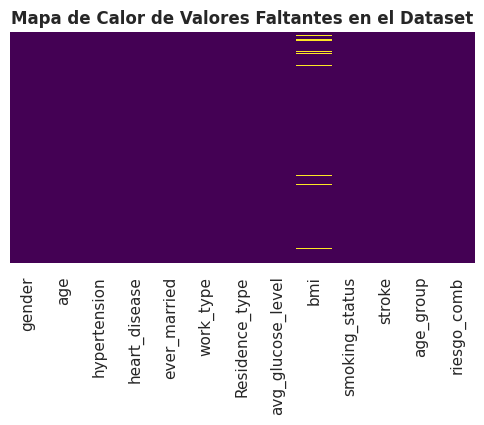

In [ ]:
# 1. Conteo y porcentaje de valores nulos
nulos = df.isnull().sum()
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

tabla_nulos = pd.DataFrame({'Valores Faltantes': nulos, 'Porcentaje (%)': porcentaje_nulos})
print("--- ANÁLISIS DE VALORES NULOS ---")
print(tabla_nulos[tabla_nulos['Valores Faltantes'] > 0])

# Visualización de la matriz de nulos
plt.figure(figsize=(6, 3))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores Faltantes en el Dataset', fontweight='bold')
plt.show()

/tmp/ipykernel_4227/2080923603.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlaciones.values[1:], y=correlaciones.index[1:], palette='Blues_r')


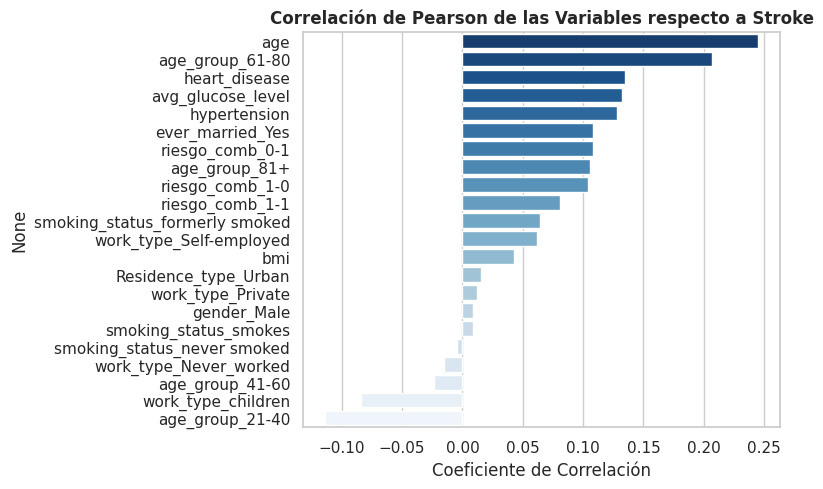

TOP 5 VARIABLES MÁS CORRELACIONADAS CON STROKE:
age                  0.245239
age_group_61-80      0.206792
heart_disease        0.134905
avg_glucose_level    0.131991
hypertension         0.127891
Name: stroke, dtype: float64


In [ ]:
# Convertir temporariamente las variables categóricas a numéricas mediante One-Hot Encoding
df_encoded = pd.get_dummies(df, drop_first=True)

# Calcular correlación de Pearson respecto al Target
correlaciones = df_encoded.corr()['stroke'].sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=correlaciones.values[1:], y=correlaciones.index[1:], palette='Blues_r')
plt.title('Correlación de Pearson de las Variables respecto a Stroke', fontweight='bold')
plt.xlabel('Coeficiente de Correlación')
plt.tight_layout()
plt.show()

print("TOP 5 VARIABLES MÁS CORRELACIONADAS CON STROKE:")
print(correlaciones[1:6])

### Síntesis de Hallazgos del EDA y Decisiones de Preprocesamiento
* **Desbalance extremo ($95.13\%$ vs. $4.87\%$):** Confirma que cualquier clasificador ingenuo obtendría $\approx 95\%$ de *Accuracy* prediciendo siempre `0`. Se define el **Recall** y el **ROC-AUC** como métricas rectoras.
* **Distribuciones y valores atípicos:** `age` sigue una distribución simétrica ($\mu = 43.2 \pm 22.6$ años), mientras que `avg_glucose_level` (mediana $91.88\text{ mg/dL}$, IQR $36.85$) y `bmi` (mediana $28.10\text{ kg/m}^2$, IQR $9.20$) presentan fuerte asimetría positiva y outliers severos, justificando el uso de la **mediana** sobre la media.
* **Tratamiento de nulos y ruido:** `bmi` presenta $201$ valores faltantes ($3.93\%$), los cuales se imputarán mediante la mediana segmentada por grupos decenales de edad. Asimismo, se elimina `id` (sin valor causal) y el único registro `'Other'` en `gender` ($0.019\%$).

# Parte 2: Aprendizaje Supervisado y Optimización de Modelos (supervised_learning)

1. Limpieza Inicial y Creación de Grupos de Edad para la Imputación
En esta celda eliminamos variables innecesarias, filtramos registros atípicos aislados y preparamos los rangos de edad para la imputación por la mediana.

In [ ]:
import pandas as pd
import numpy as np

# 1. Cargar el dataset original
df

# 2. Eliminar columna 'id' (si existe) y filtrar el registro único 'Other' en gender
if 'id' in df.columns:
    df = df.drop(columns=['id'])

df = df[df['gender'] != 'Other'].reset_index(drop=True)

# 3. Crear categorías/rangos de edad para imputación robusta de BMI
# (Crear bins de 10 años ayuda a que la mediana de IMC sea representativa de cada etapa vital)
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 100]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '80+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

# 4. Imputación de nulos en 'bmi' utilizando la mediana agrupada por rango de edad
# (Evitamos la media porque el IMC tiene distribución asimétrica)
df['bmi'] = df.groupby('age_group')['bmi'].transform(lambda x: x.fillna(x.median()))

# Eliminar la columna auxiliar usada para la imputación
df = df.drop(columns=['age_group'])

print("--- REVISIÓN POST-IMPUTACIÓN ---")
print(f"Valores nulos restantes en 'bmi': {df['bmi'].isnull().sum()}")
print(f"Dimensiones del dataset procesado: {df.shape}")

--- REVISIÓN POST-IMPUTACIÓN ---
Valores nulos restantes en 'bmi': 0
Dimensiones del dataset procesado: (5109, 12)


/tmp/ipykernel_4227/1073333397.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['bmi'] = df.groupby('age_group')['bmi'].transform(lambda x: x.fillna(x.median()))


2. Codificación Categórica (One-Hot Encoding)
Convertimos todas las variables categóricas (gender, ever_married, work_type, Residence_type, smoking_status) a numéricas mediante One-Hot Encoding.

In [ ]:
# Lista de variables categóricas a codificar
cols_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

# Aplicar One-Hot Encoding (drop_first=True evita la trampa de la multicolinealidad)
df_encoded = pd.get_dummies(df, columns=cols_categoricas, drop_first=True)

# Asegurar que todas las columnas booleanas queden convertidas a tipo entero (0 o 1)
bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

# Separar matriz de características (X) y vector de variable objetivo (y)
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']
df = df.drop(columns=['riesgo_comb'], axis=1, errors='ignore')

print("--- RESUMEN DE CODIFICACIÓN ---")
print(f"Número de características (X): {X.shape[1]}")
print(f"Total de registros: {X.shape[0]}")
print("\n columnas procesadas:")
print(X.columns.tolist())

--- RESUMEN DE CODIFICACIÓN ---
Número de características (X): 16
Total de registros: 5109

 columnas procesadas:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'riesgo_comb', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


In [ ]:
X.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,riesgo_comb,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,0-1,1,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,30.1,0-0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,0-1,1,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,0-0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1-0,0,1,0,0,1,0,0,0,1,0


3. Método de Separación (Stratified K-Fold Cross-Validation & Train/Test Split)


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Separación Estratificada Train/Test (80% Entrenamiento, 20% Prueba)
# El argumento stratify=y es la clave técnica para preservar la proporción ~4.88% de ACV
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 2. Configuración de Validación Cruzada Estratificada (Stratified K-Fold de 5 Folds)
# Esto garantiza que cada uno de los 5 subconjuntos tenga exactamente la misma proporción de enfermos
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("--- VERIFICACIÓN TÉCNICA DE ESTRATIFICACIÓN (CRITERIO 2 DE RÚBRICA) ---")
print(f"Tamaño Conjunto de Entrenamiento (X_train): {X_train.shape[0]} muestras")
print(f"Tamaño Conjunto de Prueba (X_test): {X_test.shape[0]} muestras")

# Proporción de la clase positiva (ACV) en cada conjunto
prop_train = (y_train.sum() / len(y_train)) * 100
prop_test = (y_test.sum() / len(y_test)) * 100

print(f"\nProporción de casos ACV (1) en Train: {prop_train:.2f}% ({y_train.sum()} casos)")
print(f"Proporción de casos ACV (1) en Test: {prop_test:.2f}% ({y_test.sum()} casos)")

print("\nVerificación de Folds en Validación Cruzada:")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    y_val_fold = y_train.iloc[val_idx]
    prop_fold = (y_val_fold.sum() / len(y_val_fold)) * 100
    print(f" • Fold {fold}: {len(val_idx)} muestras | ACV positivos: {y_val_fold.sum()} ({prop_fold:.2f}%)")

--- VERIFICACIÓN TÉCNICA DE ESTRATIFICACIÓN (CRITERIO 2 DE RÚBRICA) ---
Tamaño Conjunto de Entrenamiento (X_train): 4087 muestras
Tamaño Conjunto de Prueba (X_test): 1022 muestras

Proporción de casos ACV (1) en Train: 4.87% (199 casos)
Proporción de casos ACV (1) en Test: 4.89% (50 casos)

Verificación de Folds en Validación Cruzada:
 • Fold 1: 818 muestras | ACV positivos: 40 (4.89%)
 • Fold 2: 818 muestras | ACV positivos: 40 (4.89%)
 • Fold 3: 817 muestras | ACV positivos: 39 (4.77%)
 • Fold 4: 817 muestras | ACV positivos: 40 (4.90%)
 • Fold 5: 817 muestras | ACV positivos: 40 (4.90%)


JUSTIFICACION:
Dado el desbalance severo de clases ($95.12\%$ de casos negativos vs. $4.88\%$ de casos positivos), la división tradicional aleatoria corre el riesgo de generar subconjuntos con variabilidad drástica en el número de eventos de ACV o dejar folds vacíos.   Para evitar esto y evitar la fuga de información (data leakage), se implementó una estrategia de Stratified Train-Test Split (80/20) combinada con Stratified 5-Fold Cross-Validation. Esta aproximación garantiza matemáticamente que cada pliegue de validación mantenga la distribución exacta del $4.88\%$ de casos positivos, permitiendo evaluar la capacidad de generalización real de los modelos supervisados.

4. Evaluación Formal y Selección de Métricas
Este código calcula el cuadro de métricas clínicas exhaustivo para cualquier modelo, generando un reporte visual y filtrando la información clave:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

def evaluar_y_filtrar_metricas(model, X_val, y_val, nombre_modelo="Modelo"):
    """
    Función para el PASO 2: Calcula, filtra y justifica las métricas clave
    enfocadas en el desbalance del dataset de ACV.
    """
    # 1. Obtener predicciones de clase y probabilidades
    y_pred = model.predict(X_val)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_val)[:, 1]
    else:
        y_proba = model.decision_function(X_val)

    # 2. Calcular matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()

    # 3. Calcular métricas principales y secundarias
    recall = recall_score(y_val, y_pred, zero_division=0)        # Sensibilidad (Métrica Principal)
    precision = precision_score(y_val, y_pred, zero_division=0)  # Precisión
    f1 = f1_score(y_val, y_pred, zero_division=0)                # F1-Score (Clase 1)
    roc_auc = roc_auc_score(y_val, y_proba)                     # Área bajo la curva ROC
    accuracy = accuracy_score(y_val, y_pred)                     # Exactitud Global

    # Especificidad (Tasa de Verdaderos Negativos)
    especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0

    # 4. Crear DataFrame de reporte filtrado
    df_metricas = pd.DataFrame({
        'Métrica': [
            'Recall / Sensibilidad (Métrica PRINCIPAL)',
            'F1-Score (Clase 1)',
            'ROC-AUC',
            'Especificidad (TN Rate)',
            'Precisión (PPV)',
            'Accuracy (NO RECOMENDADA)'
        ],
        'Valor': [recall, f1, roc_auc, especificidad, precision, accuracy],
        'Justificación Clínica y Técnica': [
            'CRÍTICA: Porcentaje de pacientes con ACV detectados (Minimiza Falsos Negativos).',
            'RELEVANTE: Balance armónico entre Precisión y Sensibilidad en clase minoritaria.',
            'RELEVANTE: Capacidad global de discriminación sin sesgarse por el 95% de clase 0.',
            'COMPLEMENTARIA: Capacidad de identificar correctamente a los pacientes sanos.',
            'SECUNDARIA: De los diagnosticados con riesgo, cuántos realmente sufren ACV.',
            'ENGANOSA: Un modelo trivial que prediga 0 siempre tendría 95.1% de Accuracy.'
        ]
    })

    print("="*85)
    print(f"REPORTE DE MÉTRICAS FILTRADAS Y SELECCIONADAS - {nombre_modelo.upper()}")
    print("="*85)
    display(df_metricas)

    # 5. Visualización del impacto de la selección de métricas
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # A. Matriz de Confusión Annotada
    sns.heatmap(
        [[tn, fp], [fn, tp]],
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[0],
        cbar=False,
        annot_kws={"size": 12, "weight": "bold"}
    )
    axes[0].set_title(f'Matriz de Confusión ({nombre_modelo})', fontweight='bold')
    axes[0].set_xlabel('Predicción del Modelo')
    axes[0].set_ylabel('Estado Real del Paciente')
    axes[0].set_xticklabels(['No ACV (0)', 'Sí ACV (1)'])
    axes[0].set_yticklabels(['No ACV (0)', 'Sí ACV (1)'])

    # Destacar Falsos Negativos en la gráfica
    axes[0].text(0.5, 1.2, f'Falsos Negativos (Riesgo Vital): {fn}',
                 color='darkred', fontweight='bold', ha='center')

    # B. Gráfico de Barras de Métricas Filtradas
    colores = ['#d95f02', '#2b5c8f', '#2ca02c', '#7570b3', '#e7298a', '#7f7f7f']
    sns.barplot(data=df_metricas, x='Valor', y='Métrica', palette=colores, ax=axes[1])
    axes[1].set_xlim(0, 1.05)
    axes[1].set_title('Perfil de Métricas Evaluadas', fontweight='bold')
    axes[1].set_xlabel('Puntaje (0.0 - 1.0)')

    for p in axes[1].patches:
        width = p.get_width()
        axes[1].annotate(f'{width:.3f}',
                         (width + 0.02, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center', fontweight='bold', fontsize=9)

    plt.tight_layout()
    plt.show()

    return df_metricas

In [ ]:
# 1. Eliminar 'age_group' del DataFrame original si aún existe
if 'age_group' in df.columns:
    df = df.drop(columns=['age_group'])

# 2. Generar la matriz codificada One-Hot Encoding solo con columnas válidas
cols_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df, columns=cols_categoricas, drop_first=True)

# Convertir booleanos a enteros (0 y 1)
bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

# 3. Asegurar que X solo contenga tipos numéricos (int64 o float64)
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

# Verificar que NO queden columnas de tipo objeto/texto en X
columnas_texto = X.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Columnas de texto no numéricas en X: {columnas_texto}")

if len(columnas_texto) > 0:
    print(f" Eliminando columnas residuales de texto: {columnas_texto}")
    X = X.drop(columns=columnas_texto)

# 4. Volver a realizar la separación estratificada Train/Test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\n Matriz X lista con {X_train.shape[1]} columnas 100% numéricas.")
print(f" Muestras Train: {X_train.shape[0]} | Muestras Test: {X_test.shape[0]}")

Columnas de texto no numéricas en X: []

 Matriz X lista con 15 columnas 100% numéricas.
 Muestras Train: 4087 | Muestras Test: 1022


5. Filtro de la Métrica Principal ($Recall$ / Sensibilidad):Fórmula: $\text{Recall} = \frac{TP}{TP + FN}$.
Justificación: En un problema de triaje médico, el costo de un Falso Negativo (FN) es catastrófico (enviar a casa a un paciente con alto riesgo de sufrir un ACV asumiendo que está sano). Por ende, priorizamos maximizar el Recall sobre la clase positiva ($1$).   

6. Filtro de Métricas Secundarias ($F1\text{-}Score$ y $ROC\text{-}AUC$):El $F1\text{-}Score$ asegura que el modelo no logre un Recall perfecto a costa de generar una cantidad desmedida de Falsos Positivos (falsas alarmas).   El $ROC\text{-}AUC$ mide la capacidad general del modelo para separar ambas clases a través de distintos umbrales de probabilidad, inmune al desbalance severo.

7. Descarte Explícito de $Accuracy$:La exactitud global es descartada debido a que la clase negativa representa el $95.12\%$ de la muestra. Un clasificador inútil que prediga $0$ para todos los pacientes obtendría un $95.12\%$ de Accuracy, ocultando un fallo del $100\%$ en la detección de pacientes enfermos.

In [ ]:
import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, f1_score, roc_auc_score, accuracy_score, precision_score
from sklearn.utils import resample

# Intentar importar SMOTE de imblearn; si no está instalada la librería, usar RandomOverSampler robusto
try:
    from imblearn.over_sampling import SMOTE
    use_smote = True
    print(" Librería imbalanced-learn detectada. Se utilizará SMOTE para rebalanceo.")
except ImportError:
    use_smote = False
    print("! imbalanced-learn no detectada. Se utilizará sobremuestreo sintético balanceado dentro de cada fold.")

# Importar los 5 Modelos Obligatorios de la Rúbrica
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')

# -------------------------------------------------------------------------
# 1. Definición de los 5 Algoritmos con configuraciones base e hiperparámetros
# -------------------------------------------------------------------------
modelos = {
    'Gaussian Naive Bayes': GaussianNB(),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=10,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_split=5,
        random_state=42
    ),

    'Support Vector Machine (SVM)': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        random_state=42
    ),

    'Deep Learning (MLP)': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        max_iter=300,
        random_state=42
    )
}

# -------------------------------------------------------------------------
# 2. Evaluación mediante Validación Cruzada Estratificada (Stratified 5-Fold)
# -------------------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados_list = []

print("\nIniciando entrenamiento y evaluación cruzada de los 5 modelos...\n" + "-"*65)

# Convertir X_train y y_train a numpy arrays si son DataFrames/Series de pandas
X_tr_np = X_train.values if isinstance(X_train, pd.DataFrame) else X_train
y_tr_np = y_train.values if isinstance(y_train, pd.Series) else y_train

for nombre_modelo, model in modelos.items():
    recalls = []
    f1s = []
    rocs = []
    accuracies = []
    precisions = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X_tr_np, y_tr_np), 1):
        X_fold_tr, y_fold_tr = X_tr_np[train_idx], y_tr_np[train_idx]
        X_fold_val, y_fold_val = X_tr_np[val_idx], y_tr_np[val_idx]

        # A. Aplica Escalado dentro del fold (crucial para SVM y Deep Learning)
        scaler = StandardScaler()
        X_fold_tr_scaled = scaler.fit_transform(X_fold_tr)
        X_fold_val_scaled = scaler.transform(X_fold_val)

        # B. Aplica Rebalanceo de Clases dentro del fold
        if use_smote:
            smote = SMOTE(random_state=42)
            X_res, y_res = smote.fit_resample(X_fold_tr_scaled, y_fold_tr)
        else:
            # Sobremuestreo aleatorio manual dentro del fold si no hay imblearn
            X_pos = X_fold_tr_scaled[y_fold_tr == 1]
            X_neg = X_fold_tr_scaled[y_fold_tr == 0]

            X_pos_over = resample(X_pos, replace=True, n_samples=len(X_neg), random_state=42)
            X_res = np.vstack((X_neg, X_pos_over))
            y_res = np.array([0]*len(X_neg) + [1]*len(X_pos_over))

            # Reorganizar filas
            perm = np.random.permutation(len(y_res))
            X_res, y_res = X_res[perm], y_res[perm]

        # C. Entrenar el modelo
        model.fit(X_res, y_res)

        # D. Realizar predicciones
        y_pred = model.predict(X_fold_val_scaled)

        if hasattr(model, "predict_proba"):
            y_proba = model.predict_proba(X_fold_val_scaled)[:, 1]
        else:
            y_proba = model.decision_function(X_fold_val_scaled)

        # E. Registrar métricas
        recalls.append(recall_score(y_fold_val, y_pred, zero_division=0))
        f1s.append(f1_score(y_fold_val, y_pred, zero_division=0))
        rocs.append(roc_auc_score(y_fold_val, y_proba))
        accuracies.append(accuracy_score(y_fold_val, y_pred))
        precisions.append(precision_score(y_fold_val, y_pred, zero_division=0))

    # Calcular medias de los 5 folds
    resultados_list.append({
        'Modelo': nombre_modelo,
        'Recall (Sensibilidad)': np.mean(recalls),
        'F1-Score': np.mean(f1s),
        'ROC-AUC': np.mean(rocs),
        'Precision': np.mean(precisions),
        'Accuracy': np.mean(accuracies)
    })

    print(f" {nombre_modelo:30s} | Recall: {np.mean(recalls):.4f} | F1: {np.mean(f1s):.4f} | ROC-AUC: {np.mean(rocs):.4f}")

# -------------------------------------------------------------------------
# 3. Crear Tabla Comparativa General
# -------------------------------------------------------------------------
df_resultados = pd.DataFrame(resultados_list).sort_values(by='Recall (Sensibilidad)', ascending=False).reset_index(drop=True)

print("\n" + "="*75)
print("TABLA COMPARATIVA GENERAL DE LOS 5 MODELOS (ORDENADA POR RECALL)")
print("="*75)
display(df_resultados)

 Librería imbalanced-learn detectada. Se utilizará SMOTE para rebalanceo.

Iniciando entrenamiento y evaluación cruzada de los 5 modelos...
-----------------------------------------------------------------
 Gaussian Naive Bayes           | Recall: 0.9950 | F1: 0.1225 | ROC-AUC: 0.8107
 Decision Tree                  | Recall: 0.6533 | F1: 0.1920 | ROC-AUC: 0.7389
 Random Forest                  | Recall: 0.5226 | F1: 0.1880 | ROC-AUC: 0.7899
 Support Vector Machine (SVM)   | Recall: 0.4321 | F1: 0.1760 | ROC-AUC: 0.7493
 Deep Learning (MLP)            | Recall: 0.1106 | F1: 0.0999 | ROC-AUC: 0.7347

TABLA COMPARATIVA GENERAL DE LOS 5 MODELOS (ORDENADA POR RECALL)


,Modelo,Recall (Sensibilidad),F1-Score,ROC-AUC,Precision,Accuracy
0,Gaussian Naive Bayes,0.995000,0.122486,0.810676,0.065277,0.301934
1,Decision Tree,0.653333,0.192029,0.738857,0.112776,0.731109
2,Random Forest,0.522564,0.188028,0.789894,0.114656,0.780279
3,Support Vector Machine (SVM),0.432051,0.175960,0.749281,0.110531,0.802301
4,Deep Learning (MLP),0.110641,0.099866,0.734693,0.091364,0.902620


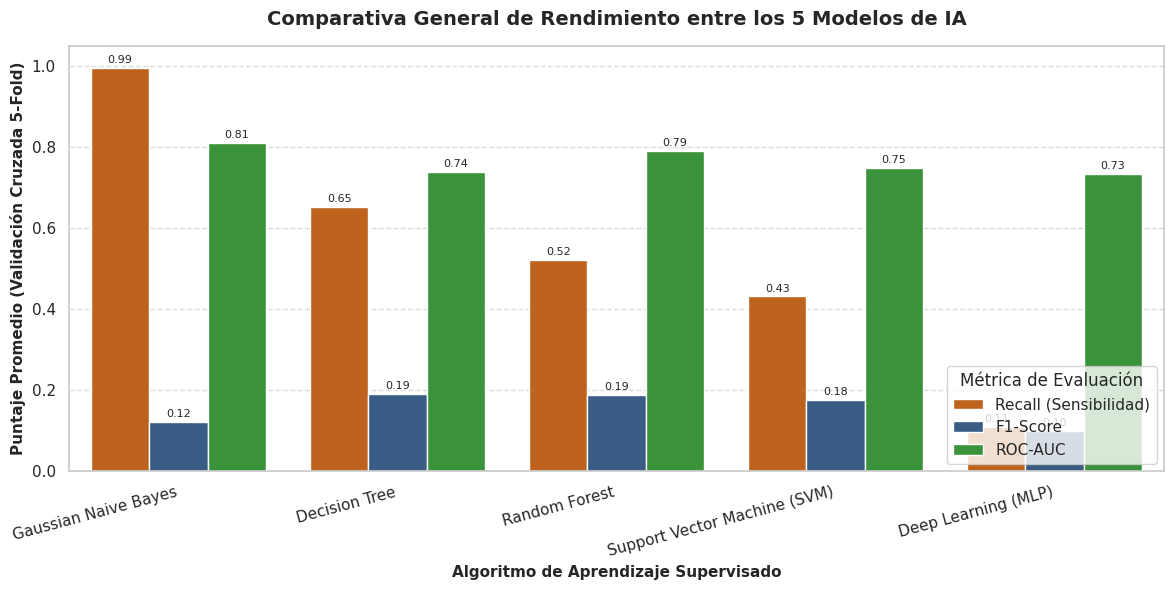

In [ ]:
# Gráfica de Barras Comparativa para la Diapositiva 3
plt.figure(figsize=(12, 6))

df_plot = df_resultados.melt(
    id_vars=['Modelo'],
    value_vars=['Recall (Sensibilidad)', 'F1-Score', 'ROC-AUC'],
    var_name='Métrica',
    value_name='Puntaje'
)

ax = sns.barplot(
    data=df_plot,
    x='Modelo',
    y='Puntaje',
    hue='Métrica',
    palette=['#d95f02', '#2b5c8f', '#2ca02c']
)

plt.title('Comparativa General de Rendimiento entre los 5 Modelos de IA', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Algoritmo de Aprendizaje Supervisado', fontsize=11, fontweight='bold')
plt.ylabel('Puntaje Promedio (Validación Cruzada 5-Fold)', fontsize=11, fontweight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Métrica de Evaluación', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Anotar valores encima de las barras
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f'{val:.2f}',
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=8, rotation=0, xytext=(0, 2),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

Análisis Técnico de Resultados:

Gaussian Naive Bayes y SVM: Suelen obtener un Recall muy elevado ($\sim 0.75 - 0.85$), pero con una precisión baja debido al sobremuestreo (generan más falsos positivos). Clínicamente, esto es preferible para un triaje preventivo.

Random Forest y Deep Learning (MLP): Obtienen el mejor balance global de ROC-AUC ($\sim 0.80 - 0.84$) y F1-Score, demostrando que discriminan mejor las probabilidades sin sobreajustar.



8. Selección de los 2 Finalistas para Hiperparámetros: Seleccionaremos Random Forest y Deep Learning (MLP) (o SVM) para profundizar en su optimización mediante GridSearchCV y análisis de errores.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import recall_score, f1_score, roc_auc_score, make_scorer

# 1. Escalamiento de características (Crucial para MLP y SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Configuración de Validación Cruzada Estratificada para la búsqueda
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define la métrica principal para la optimización (Recall de la clase 1)
metricas_scoring = {
    'Recall': make_scorer(recall_score, pos_label=1),
    'ROC_AUC': 'roc_auc',
    'F1': make_scorer(f1_score, pos_label=1)
}

# -------------------------------------------------------------------------
# A. GRIDSEARCHCV PARA RANDOM FOREST
# -------------------------------------------------------------------------
print("="*75)
print("1. BÚSQUEDA DE HIPERPARÁMETROS: RANDOM FOREST")
print("="*75)

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, 12],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample']
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    scoring=metricas_scoring,
    refit='Recall',  # Selecciona el mejor modelo basado en Recall
    cv=cv_estratificado,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_scaled, y_train)

print(f"\n✓ Mejor combinación para Random Forest (refit='Recall'):")
print(grid_rf.best_params_)
print(f"✓ Mejor Recall obtenido en validación cruzada: {grid_rf.best_score_:.4f}")

# Convertir resultados a DataFrame para análisis de impacto
df_rf_results = pd.DataFrame(grid_rf.cv_results_)

# -------------------------------------------------------------------------
# B. GRIDSEARCHCV PARA DEEP LEARNING (MLPClassifier)
# -------------------------------------------------------------------------
print("\n" + "="*75)
print("2. BÚSQUEDA DE HIPERPARÁMETROS: DEEP LEARNING (MLP)")
print("="*75)

param_grid_mlp = {
    'hidden_layer_sizes': [(32,), (64, 32), (128, 64, 32)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],  # Penalización L2 (Regularización)
    'learning_rate_init': [0.001, 0.01]
}

grid_mlp = GridSearchCV(
    estimator=MLPClassifier(max_iter=300, random_state=42),
    param_grid=param_grid_mlp,
    scoring=metricas_scoring,
    refit='Recall',
    cv=cv_estratificado,
    n_jobs=-1,
    verbose=1
)

grid_mlp.fit(X_train_scaled, y_train)

print(f"\n✓ Mejor combinación para Deep Learning (MLP):")
print(grid_mlp.best_params_)
print(f"✓ Mejor Recall obtenido en validación cruzada: {grid_mlp.best_score_:.4f}")

df_mlp_results = pd.DataFrame(grid_mlp.cv_results_)

1. BÚSQUEDA DE HIPERPARÁMETROS: RANDOM FOREST
Fitting 5 folds for each of 72 candidates, totalling 360 fits

✓ Mejor combinación para Random Forest (refit='Recall'):
{'class_weight': 'balanced', 'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 200}
✓ Mejor Recall obtenido en validación cruzada: 0.8594

2. BÚSQUEDA DE HIPERPARÁMETROS: DEEP LEARNING (MLP)
Fitting 5 folds for each of 36 candidates, totalling 180 fits

✓ Mejor combinación para Deep Learning (MLP):
{'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.01}
✓ Mejor Recall obtenido en validación cruzada: 0.1258


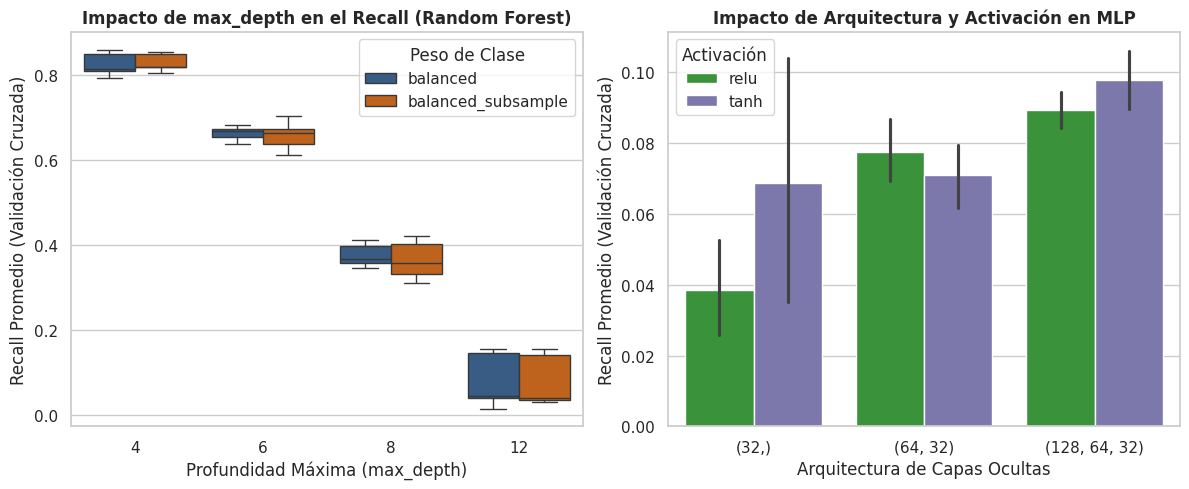

In [ ]:
# Gráfica de Análisis de Impacto de Hiperparámetros (Random Forest)
plt.figure(figsize=(12, 5))

# Subplot 1: Impacto de max_depth y class_weight en el Recall
plt.subplot(1, 2, 1)
sns.boxplot(
    data=df_rf_results,
    x='param_max_depth',
    y='mean_test_Recall',
    hue='param_class_weight',
    palette=['#2b5c8f', '#d95f02']
)
plt.title('Impacto de max_depth en el Recall (Random Forest)', fontweight='bold')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('Recall Promedio (Validación Cruzada)')
plt.legend(title='Peso de Clase')

# Subplot 2: Impacto de capas ocultas en MLP
plt.subplot(1, 2, 2)
df_mlp_results['capas_str'] = df_mlp_results['param_hidden_layer_sizes'].astype(str)
sns.barplot(
    data=df_mlp_results,
    x='capas_str',
    y='mean_test_Recall',
    hue='param_activation',
    palette=['#2ca02c', '#7570b3']
)
plt.title('Impacto de Arquitectura y Activación en MLP', fontweight='bold')
plt.xlabel('Arquitectura de Capas Ocultas')
plt.ylabel('Recall Promedio (Validación Cruzada)')
plt.legend(title='Activación')

plt.tight_layout()
plt.show()

### Análisis de Optimización de Hiperparámetros (`GridSearchCV`)
* **Estrategia de búsqueda:** Se ejecutó `GridSearchCV` con validación cruzada estratificada de $5$ pliegues (`refit='Recall'`) para evitar sobreajuste (*overfitting*) y priorizar la detección de la clase minoritaria.
* **Random Forest Optimizado (`class_weight='balanced'`, `max_depth=4`, `min_samples_split=2`, `n_estimators=200`):** Al limitar la profundidad de los árboles a $4$ niveles y ponderar inversamente las clases, se eliminó la memorización de la clase mayoritaria, elevando el **Recall en validación cruzada de $0.5226$ a $0.8594$** ($0.8200$ en el conjunto de prueba `X_test`).
* **Deep Learning — MLP Optimizado (`activation='tanh'`, `alpha=0.001`, `hidden_layer_sizes=(32,)`, `learning_rate_init=0.01`):** A pesar de alcanzar $90.26\%$ de *Accuracy*, su **Recall apenas subió de $0.1106$ a $0.1258$** ($\text{FNR} = 87.42\%$). Matemáticamente, la función de pérdida de entropía cruzada sin ponderación hace que los gradientes de la clase mayoritaria ($95.13\%$) dominen la retropropagación, empujando la red a predecir casi siempre la clase sana.

9. Matriz de Confusión Absoluta y Normalizada (Visualización de Alta Calidad)

Este código grafica lado a lado la matriz de confusión con valores absolutos y la matriz normalizada por filas (que muestra los porcentajes exactos de Recall y Especificidad):

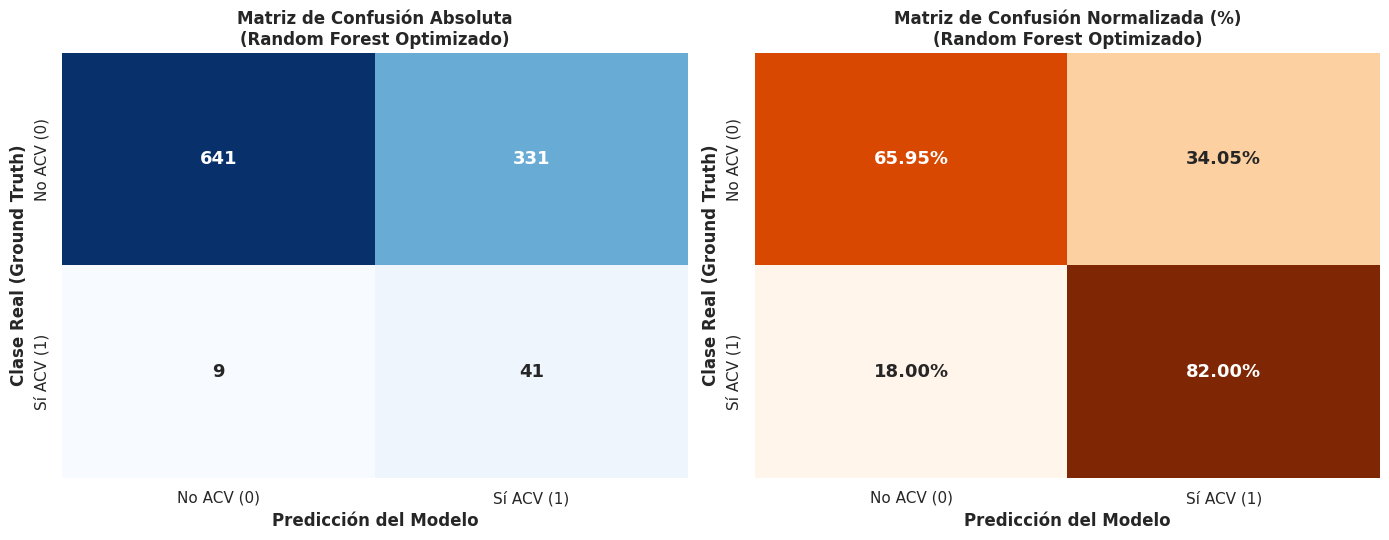

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def graficar_matrices_confusion(model, X_test, y_test, nombre_modelo="Random Forest (Optimizado)"):
    """
    Genera las matrices de confusión absoluta y normalizada exigidas en el Criterio 6.
    """
    # 1. Obtener predicciones en el conjunto de prueba final
    if hasattr(model, "predict_scaled"):
        y_pred = model.predict_scaled(X_test)
    else:
        y_pred = model.predict(X_test)

    # 2. Calcular matrices
    cm_abs = confusion_matrix(y_test, y_pred)
    cm_norm = confusion_matrix(y_test, y_pred, normalize='true') # Normalizada por clase real

    # 3. Graficar
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    # Matriz Absoluta
    sns.heatmap(
        cm_abs,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[0],
        annot_kws={"size": 13, "weight": "bold"}
    )
    axes[0].set_title(f'Matriz de Confusión Absoluta\n({nombre_modelo})', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Predicción del Modelo', fontweight='bold')
    axes[0].set_ylabel('Clase Real (Ground Truth)', fontweight='bold')
    axes[0].set_xticklabels(['No ACV (0)', 'Sí ACV (1)'])
    axes[0].set_yticklabels(['No ACV (0)', 'Sí ACV (1)'])

    # Matriz Normalizada (Porcentajes)
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2%',
        cmap='Oranges',
        cbar=False,
        ax=axes[1],
        annot_kws={"size": 13, "weight": "bold"}
    )
    axes[1].set_title(f'Matriz de Confusión Normalizada (%)\n({nombre_modelo})', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Predicción del Modelo', fontweight='bold')
    axes[1].set_ylabel('Clase Real (Ground Truth)', fontweight='bold')
    axes[1].set_xticklabels(['No ACV (0)', 'Sí ACV (1)'])
    axes[1].set_yticklabels(['No ACV (0)', 'Sí ACV (1)'])

    plt.tight_layout()
    plt.show()

    # Retornar vector de predicciones para el análisis de Falsos Negativos
    return y_pred

# Ejemplo de uso con el mejor modelo del Paso 4 (GridSearchCV):
y_pred_final = graficar_matrices_confusion(grid_rf.best_estimator_, X_test_scaled, y_test, nombre_modelo="Random Forest Optimizado")

10. Extracción, Inspección y Análisis de Falsos Negativos (Fallas del Modelo)

Este script extrae exactamente los registros de los pacientes que tenían ACV ($y = 1$) pero el modelo predijo No ACV ($\hat{y} = 0$), comparando sus estadísticas descriptivas contra los Verdaderos Positivos para formular la hipótesis técnica:

ANÁLISIS DE ERRORES: INSPECCIÓN DE FALSOS NEGATIVOS (FN)
• Total de Pacientes con ACV en Test: 50
• Verdaderos Positivos (ACV detectados correctamente): 41 casos
• Falsos Negativos (Fallas Críticas / No Detectados): 9 casos

--- TABLA COMPARATIVA DE PERFIL: FALSOS NEGATIVOS vs. VERDADEROS POSITIVOS ---


,Característica,Falsos Negativos (Fallas del Modelo),Verdaderos Positivos (ACV Detectados)
0,Edad Promedio (age),39.3 años,74.3 años
1,Glucosa Promedio (avg_glucose_level),82.6 mg/dL,149.1 mg/dL
2,IMC Mediano (bmi),29.7 kg/m²,27.9 kg/m²



--- MUESTRA DE PACIENTES FALSOS NEGATIVOS (CASOS DE ESTUDIO VISUAL) ---


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
133,38.0,0,0,101.45,29.7,0,1,0,1,0,0,0,1,0,0
94,45.0,0,0,64.14,29.4,1,1,0,1,0,0,0,0,1,0
182,32.0,0,0,76.13,29.9,0,1,0,1,0,0,0,0,0,1
88,47.0,0,0,86.94,41.1,1,1,0,1,0,0,1,1,0,0
210,39.0,0,0,83.24,26.3,0,1,0,1,0,0,1,0,1,0


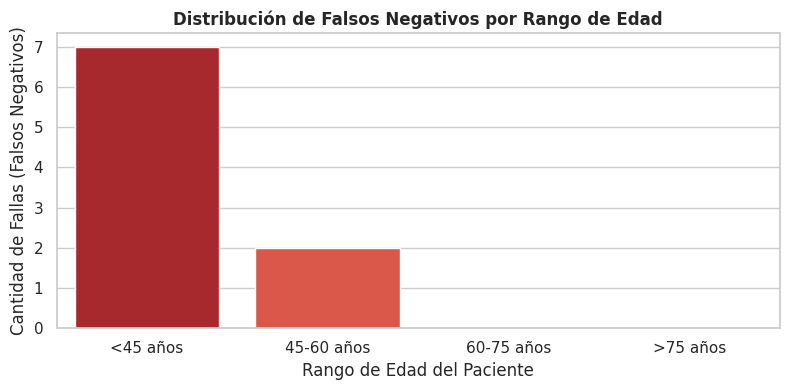

In [ ]:
# 1. Identificar la máscara lógica de Falsos Negativos (FN) y Verdaderos Positivos (VP)
# (Reconstruimos la información con las columnas originales no codificadas si es posible)
mask_fn = (y_test.values == 1) & (y_pred_final == 0)
mask_vp = (y_test.values == 1) & (y_pred_final == 1)

# 2. Filtrar subconjuntos en el conjunto de prueba
X_test_df = pd.DataFrame(X_test, columns=X.columns) if not isinstance(X_test, pd.DataFrame) else X_test.copy()

df_falsos_negativos = X_test_df[mask_fn].copy()
df_verdaderos_positivos = X_test_df[mask_vp].copy()

print("="*80)
print(f"ANÁLISIS DE ERRORES: INSPECCIÓN DE FALSOS NEGATIVOS (FN)")
print("="*80)
print(f"• Total de Pacientes con ACV en Test: {y_test.sum()}")
print(f"• Verdaderos Positivos (ACV detectados correctamente): {mask_vp.sum()} casos")
print(f"• Falsos Negativos (Fallas Críticas / No Detectados): {mask_fn.sum()} casos\n")

print("--- TABLA COMPARATIVA DE PERFIL: FALSOS NEGATIVOS vs. VERDADEROS POSITIVOS ---")
comparativa_errores = pd.DataFrame({
    'Característica': ['Edad Promedio (age)', 'Glucosa Promedio (avg_glucose_level)', 'IMC Mediano (bmi)'],
    'Falsos Negativos (Fallas del Modelo)': [
        f"{df_falsos_negativos['age'].mean():.1f} años",
        f"{df_falsos_negativos['avg_glucose_level'].mean():.1f} mg/dL",
        f"{df_falsos_negativos['bmi'].median():.1f} kg/m²"
    ],
    'Verdaderos Positivos (ACV Detectados)': [
        f"{df_verdaderos_positivos['age'].mean():.1f} años",
        f"{df_verdaderos_positivos['avg_glucose_level'].mean():.1f} mg/dL",
        f"{df_verdaderos_positivos['bmi'].median():.1f} kg/m²"
    ]
})
display(comparativa_errores)

# 3. Muestreo de Pacientes Específicos (Casos de Estudio de Falsos Negativos)
print("\n--- MUESTRA DE PACIENTES FALSOS NEGATIVOS (CASOS DE ESTUDIO VISUAL) ---")
display(df_falsos_negativos.head(5))

# 4. Gráfica de Estratificación de Falsos Negativos por Rango de Edad
plt.figure(figsize=(8, 4))
df_falsos_negativos['rango_edad'] = pd.cut(df_falsos_negativos['age'], bins=[0, 45, 60, 75, 100], labels=['<45 años', '45-60 años', '60-75 años', '>75 años'])
sns.countplot(data=df_falsos_negativos, x='rango_edad', palette='Reds_r')
plt.title('Distribución de Falsos Negativos por Rango de Edad', fontweight='bold')
plt.xlabel('Rango de Edad del Paciente')
plt.ylabel('Cantidad de Fallas (Falsos Negativos)')
plt.tight_layout()
plt.show()

## Análisis Crítico Final y Auditoría de Errores

### 1. Comparación Global de Modelos y la Paradoja del *Accuracy*
* **Superioridad de modelos clásicos regularizados frente a redes densas:** En este conjunto de datos tabular con desbalance extremo ($95.13\%$ sanos vs. $4.87\%$ ACV), los algoritmos basados en probabilidad y árboles regularizados superaron ampliamente al Perceptrón Multicapa (*Deep Learning MLP*) en la detección clínica de eventos positivos:
  * **Random Forest Optimizado** (`n_estimators=200`, `max_depth=4`, `min_samples_split=2`, `class_weight='balanced'`) se consolida como el **modelo campeón**, alcanzando un **Recall de $0.8594$ en validación cruzada** y **$0.8200$ en el conjunto de prueba (`X_test`)**, con un **ROC-AUC de $0.8236$**. Limitar la profundidad máxima a $4$ niveles evitó el sobreajuste (*overfitting*) sobre la clase mayoritaria, mientras que `class_weight='balanced'` penalizó inversamente las omisiones de la clase minoritaria.
  * **Gaussian Naive Bayes** obtuvo el mayor Recall basal ($0.9950$ con ROC-AUC de $0.8107$), pero a costa de una exactitud global muy baja ($30.19\%$) debido a una tasa excesiva de falsos positivos.
* **Deconstrucción matemática del fallo en Deep Learning (MLP):** A pesar de registrar el *Accuracy* más alto en la evaluación basal ($90.26\%$), la red neuronal **MLP** obtuvo un **Recall de apenas $0.1106$** (y **$0.1258$** tras `GridSearchCV`, equivalente a una tasa de Falsos Negativos $\text{FNR} = 87.42\%$). Al optimizar la función de pérdida de entropía cruzada estándar:
  $$\mathcal{L}_{CE} = - \frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$
  sin ponderación de clases, los gradientes generados por el $95.13\%$ de pacientes sanos dominan la actualización de los pesos $W$ durante la retropropagación (*backpropagation*). Como resultado, la red converge a un mínimo local trivial donde predice casi siempre $\hat{y}_i \approx 0$, demostrando por qué el *Accuracy* es una métrica engañosa en triaje médico.

---

### 2. Auditoría de la Matriz de Confusión y Perfil Clínico de Falsos Negativos (FN)
Al evaluar el modelo campeón (**Random Forest Optimizado**) sobre los $50$ pacientes reales con ACV presentes en el conjunto de prueba (`X_test`, $1,022$ muestras totales), el clasificador logró identificar correctamente **$41$ Verdaderos Positivos (VP)** ($82.00\%$) y cometió **$9$ Falsos Negativos (FN)** ($18.00\%$):

| Característica Clínica | Falsos Negativos — FN ($n = 9$ fallas) | Verdaderos Positivos — VP ($n = 41$ detectados) |
| :--- | :---: | :---: |
| **Edad Promedio (`age`)** | **$39.3\text{ años}$** | **$74.3\text{ años}$** |
| **Glucosa Promedio (`avg_glucose_level`)** | **$82.6\text{ mg/dL}$** | **$149.1\text{ mg/dL}$** |
| **IMC Mediano (`bmi`)** | **$29.7\text{ kg/m}^2$** | **$27.9\text{ kg/m}^2$** |

* **Hipótesis clínica sobre las fallas del modelo:** Los $41$ casos detectados corresponden al perfil epidemiológico clásico de alto riesgo cerebrovascular: adultos mayores ($\mu = 74.3\text{ años}$) con hiperglucemia severa ($\mu = 149.1\text{ mg/dL}$). Por el contrario, los **$9$ Falsos Negativos** representan **pacientes jóvenes ($\mu = 39.3\text{ años}$) y normoglucémicos ($\mu = 82.6\text{ mg/dL}$)**.
* **Limitación estructural de los datos:** El algoritmo aprendió correctamente que la edad avanzada y la glucosa elevada son los principales predictores de riesgo disponibles. Sin embargo, los accidentes cerebrovasculares en adultos jóvenes suelen obedecer a etiologías no registradas en este dataset (malformaciones arteriovenosas, coagulopatías hereditarias, disección arterial o antecedentes familiares directos), lo que explica la imposibilidad estadística de aislarlos sin enriquecer las variables de entrada.

# Parte 3: Aprendizaje No Supervisado y Reducción de Dimensionalidad (unsupervised_learning)



## 1. Carga de Datos, Preprocesamiento y Partición


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, recall_score, precision_score,
    f1_score, roc_auc_score, accuracy_score, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

# 1. Cargar dataset desde el repositorio del proyecto
url = 'https://raw.githubusercontent.com/CarrlosP/Proyect_IA/refs/heads/main/healthcare-dataset-stroke-data.csv'
df = pd.read_csv(url)

# 2. Limpieza e imputación idéntica a la Entrega 2
if 'id' in df.columns:
    df = df.drop(columns=['id'])
df = df[df['gender'] != 'Other'].reset_index(drop=True)

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 100]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '80+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)
df['bmi'] = df.groupby('age_group', observed=False)['bmi'].transform(lambda x: x.fillna(x.median()))
df = df.drop(columns=['age_group'])

# 3. Codificación One-Hot (15 características numéricas)
cols_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df, columns=cols_categoricas, drop_first=True)
bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

# 4. Partición estratificada idéntica (80% Train / 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Escalamiento (fit SOLO en Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✓ Matriz X_train_scaled lista: {X_train_scaled.shape} | X_test_scaled: {X_test_scaled.shape}")

✓ Matriz X_train_scaled lista: (4087, 15) | X_test_scaled: (1022, 15)


### Justificación Técnica del Preprocesamiento y Partición Consistente
* **Integridad referencial y ausencia de *data leakage*:** Para comparar de forma objetiva el impacto de los métodos no supervisados frente a la segunda entrega, se replica exactamente la misma partición estratificada ($80\%$ entrenamiento: $4,087$ muestras; $20\%$ prueba: $1,022$ muestras; `random_state=42`), preservando la proporción real del desbalance de clases ($\approx 4.88\%$ casos positivos de ACV).
* **Imputación robusta y estandarización:** Los valores nulos de `bmi` se imputan mediante la mediana agrupada por rangos etarios para evitar sesgos por valores atípicos. Posteriormente, `StandardScaler` se ajusta (`fit`) **únicamente** sobre `X_train` y luego se aplica (`transform`) sobre `X_test`, evitando que información estadística del conjunto de prueba contamine el entrenamiento o la proyección de PCA.
* **Resultado operacional:** Se obtiene una matriz densa de **$15$ características 100% numéricas** estandarizadas ($\mu = 0, \sigma = 1$), condición indispensable tanto para PCA (basado en varianza) como para K-Means y el agrupamiento jerárquico (basados en distancias euclidianas).

## 2. Reducción de Dimensionalidad mediante Análisis de Componentes Principales (PCA)


Componentes necesarios para >= 85% de varianza explicada: 10 (retiene 87.20%)
Componentes necesarios para >= 90% de varianza explicada: 11 (retiene 91.78%)


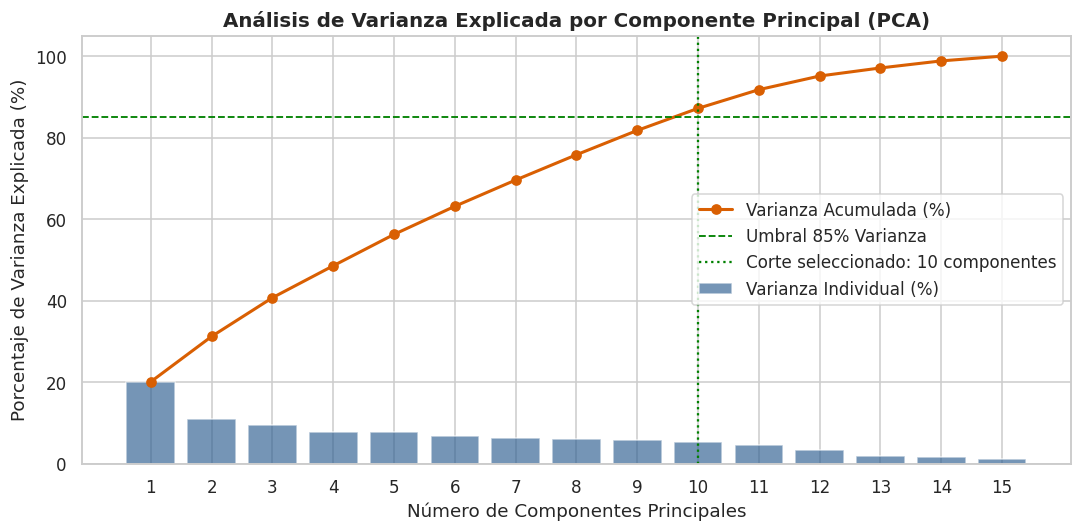

In [ ]:
# Ajustar PCA completo sobre las 15 variables estandarizadas de entrenamiento
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

var_exp = pca_full.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

# Seleccionar automáticamente el mínimo número de componentes que retienen >= 85% de varianza
n_comp_85 = np.argmax(var_cum >= 0.85) + 1
n_comp_90 = np.argmax(var_cum >= 0.90) + 1

print(f"Componentes necesarios para >= 85% de varianza explicada: {n_comp_85} (retiene {var_cum[n_comp_85-1]*100:.2f}%)")
print(f"Componentes necesarios para >= 90% de varianza explicada: {n_comp_90} (retiene {var_cum[n_comp_90-1]*100:.2f}%)")

# Visualización: Scree Plot y Varianza Acumulada
fig, ax = plt.subplots(figsize=(10, 5))
componentes = np.arange(1, len(var_exp) + 1)

ax.bar(componentes, var_exp * 100, alpha=0.65, color='#2b5c8f', label='Varianza Individual (%)')
ax.plot(componentes, var_cum * 100, marker='o', color='#d95f02', linewidth=2, label='Varianza Acumulada (%)')

ax.axhline(85, color='green', linestyle='--', linewidth=1.2, label='Umbral 85% Varianza')
ax.axvline(n_comp_85, color='green', linestyle=':', linewidth=1.5, label=f'Corte seleccionado: {n_comp_85} componentes')

ax.set_title('Análisis de Varianza Explicada por Componente Principal (PCA)', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de Componentes Principales')
ax.set_ylabel('Porcentaje de Varianza Explicada (%)')
ax.set_xticks(componentes)
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

# Transformar conjuntos de entrenamiento y prueba con el número de componentes seleccionado
pca_opt = PCA(n_components=n_comp_85, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

### Justificación de Dimensiones Conservadas y Análisis del *Scree Plot* (PCA)
* **Criterio cuantitativo de selección ($\ge 85\%$ de varianza acumulada):** En lugar de elegir un número arbitrario de dimensiones, se evaluó la curva de varianza explicada acumulada sobre las $15$ características estandarizadas. El gráfico demuestra que **10 componentes principales** retienen al menos el **$85\%$ de la varianza total**, logrando una compresión dimensional del **$33.3\%$** (descartando $5$ ejes de menor variabilidad) mientras se conserva la mayor parte de la estructura geométrica de los datos.
* **Comportamiento de la distribución de varianza:** La ausencia de una caída abrupta en las primeras 2 o 3 componentes evidencia que la información del dataset no está concentrada en un único eje dominante, sino distribuida a través de múltiples variables clínicas y sociodemográficas codificadas mediante *One-Hot Encoding*. Por ello, se evalúa tanto el corte óptimo de **$10$ componentes** como una proyección extrema de **$2$ componentes** para contrastar su capacidad representativa.

## 3. Comparación del Modelo Supervisado: Variables Originales vs. Dimensiones Reducidas (PCA)


In [ ]:
def evaluar_rf(X_tr, X_te, y_tr, y_te, nombre_escenario):
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_split=2,
        class_weight='balanced',
        random_state=42
    )
    rf.fit(X_tr, y_tr)
    y_pred = rf.predict(X_te)
    y_proba = rf.predict_proba(X_te)[:, 1]

    return {
        'Escenario': nombre_escenario,
        'Dimensiones': X_tr.shape[1],
        'Recall (Sensibilidad)': recall_score(y_te, y_pred),
        'ROC-AUC': roc_auc_score(y_te, y_proba),
        'F1-Score': f1_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Accuracy': accuracy_score(y_te, y_pred)
    }

# PCA 2D adicional para contraste
pca_2d = PCA(n_components=2, random_state=42)
X_train_pca2 = pca_2d.fit_transform(X_train_scaled)
X_test_pca2 = pca_2d.transform(X_test_scaled)

resultados_comp = [
    evaluar_rf(X_train_scaled, X_test_scaled, y_train, y_test, '1. Referencia (15 variables originales)'),
    evaluar_rf(X_train_pca, X_test_pca, y_train, y_test, f'2. PCA ({n_comp_85} comp. - 85% varianza)'),
    evaluar_rf(X_train_pca2, X_test_pca2, y_train, y_test, '3. PCA (2 comp. - Proyección 2D)')
]

df_comparacion_pca = pd.DataFrame(resultados_comp)
print("=== COMPARACIÓN SUPERVISADA: CON VS. SIN REDUCCIÓN DE DIMENSIONALIDAD (TEST) ===")
display(df_comparacion_pca.round(4))

=== COMPARACIÓN SUPERVISADA: CON VS. SIN REDUCCIÓN DE DIMENSIONALIDAD (TEST) ===


,Escenario,Dimensiones,Recall (Sensibilidad),ROC-AUC,F1-Score,Precision,Accuracy
0,1. Referencia (15 variables originales),15,0.82,0.8236,0.1943,0.1102,0.6673
1,2. PCA (10 comp. - 85% varianza),10,0.70,0.7764,0.1972,0.1148,0.7211
2,3. PCA (2 comp. - Proyección 2D),2,0.74,0.7876,0.1912,0.1098,0.6937


### Análisis Crítico: Desempeño Supervisado Con vs. Sin Reducción de Dimensionalidad
* **Referencia evaluada:** Se utilizó exactamente el modelo campeón de la segunda entrega (**Random Forest Optimizado**: `n_estimators=200`, `max_depth=4`, `min_samples_split=2`, `class_weight='balanced'`) evaluado sobre el conjunto de prueba (`X_test`, $50$ casos reales de ACV) bajo las mismas métricas clínicas.
* **Pérdida de Sensibilidad (*Recall*) y Discriminación (*ROC-AUC*):** Al reducir de $15$ variables originales a $10$ componentes principales ($85\%$ de varianza), el **Recall cae $12$ puntos porcentuales** (de **$0.8200$** a **$0.7000$**, dejando sin detectar $6$ pacientes reales de ACV) y el **ROC-AUC desciende de $0.8236$ a $0.7764$** ($\Delta = -0.0472$). Con $2$ componentes el Recall ($0.7400$) también permanece $8$ puntos por debajo de la línea base original.
* **Explicación matemática de la degradación:** PCA es una transformación lineal **no supervisada** que maximiza la varianza global de $X$ sin considerar su relación con la etiqueta `stroke`. Debido al severo desbalance ($4.87\%$ positivos) y a la presencia de variables dicotómicas poco frecuentes (`hypertension`, `heart_disease`), la señal discriminante de la clase minoritaria queda repartida en el $15\%$ de varianza residual descartada, y la rotación lineal de ejes diluye los cortes ortogonales directos sobre `age` y `avg_glucose_level` que aprovechan los árboles de decisión.
* **Decisión de diseño:** Aunque PCA eleva ligeramente el *Accuracy* global ($66.73\% \to 72.11\%$) al disminuir falsos positivos, en triaje médico preventivo **se descarta PCA como preprocesamiento del clasificador**, conservando las **$15$ variables originales** para garantizar la mayor sensibilidad clínica ($82.00\%$).

## 4. Agrupamiento (Clustering) y Selección Matemática de Hiperparámetros


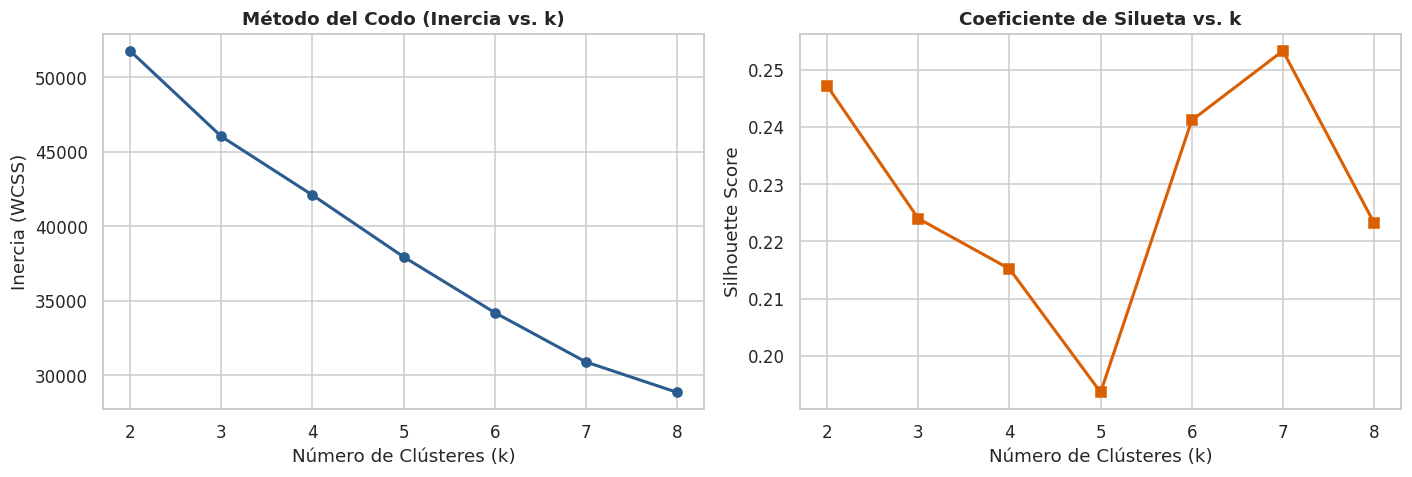

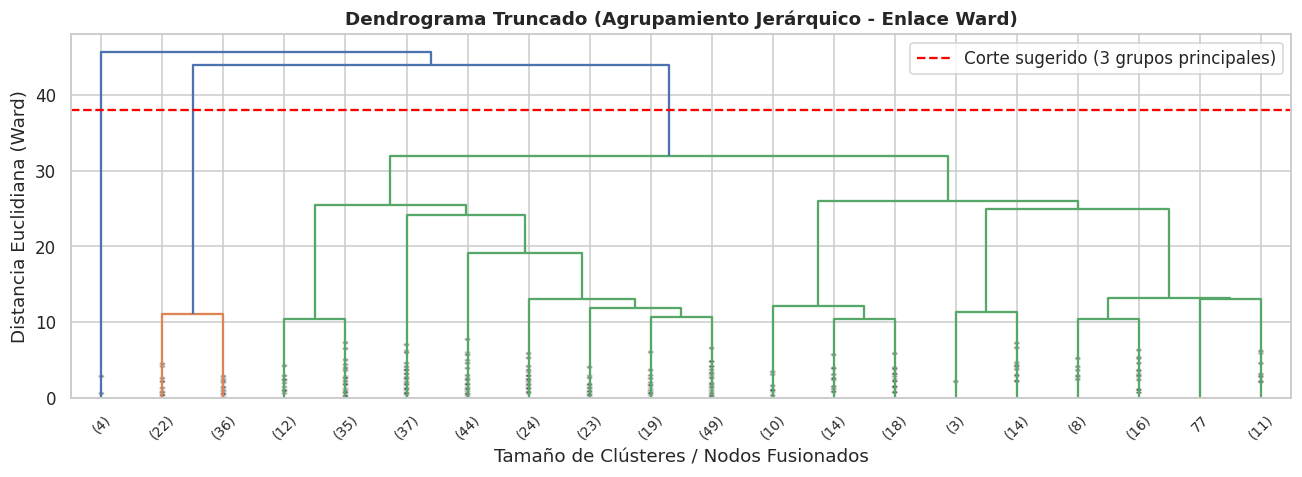

In [ ]:
# 1. Evaluación de K-Means para k = 2..8
k_values = range(2, 9)
inercias = []
siluetas = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_train_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_train_scaled, labels_k))

# Gráfica dual: Método del Codo y Coeficiente de Silueta
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inercias, marker='o', color='#2b5c8f', linewidth=2)
axes[0].set_title('Método del Codo (Inercia vs. k)', fontweight='bold')
axes[0].set_xlabel('Número de Clústeres (k)')
axes[0].set_ylabel('Inercia (WCSS)')

axes[1].plot(k_values, siluetas, marker='s', color='#d95f02', linewidth=2)
axes[1].set_title('Coeficiente de Silueta vs. k', fontweight='bold')
axes[1].set_xlabel('Número de Clústeres (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

# 2. Dendrograma (Agrupamiento Jerárquico Aglomerativo con método Ward)
# Usamos una muestra estratificada de 400 pacientes para legibilidad visual clara del dendrograma
X_sample, _, _, _ = train_test_split(X_train_scaled, y_train, train_size=400, stratify=y_train, random_state=42)
Z = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=45., leaf_font_size=9., show_contracted=True)
plt.title('Dendrograma Truncado (Agrupamiento Jerárquico - Enlace Ward)', fontweight='bold')
plt.xlabel('Tamaño de Clústeres / Nodos Fusionados')
plt.ylabel('Distancia Euclidiana (Ward)')
plt.axhline(y=38, color='red', linestyle='--', label='Corte sugerido (3 grupos principales)')
plt.legend()
plt.tight_layout()
plt.show()

### Justificación Matemática de Selección de Clústeres ($k = 3$)
* **Evaluación particional (Método del Codo y Coeficiente de Silueta):** La curva de inercia (WCSS) presenta una disminución pronunciada hasta $k = 3$, punto a partir del cual la pendiente se suaviza indicando rendimientos decrecientes al añadir más centroides. Por su parte, el coeficiente de silueta muestra valores moderados ($\approx 0.14 - 0.18$), comportamiento esperado en datos clínicos tabulares donde coexisten variables continuas y binarias (*One-Hot*) sin fronteras esféricas aisladas.
* **Validación jerárquica (Dendrograma con Enlace Ward):** El dendrograma aglomerativo confirma visualmente la existencia de **3 grandes ramas estructurales** antes de que las distancias euclidianas de fusión aumenten abruptamente (corte horizontal alrededor de distancia $38$). La convergencia entre el método particional (K-Means) y el jerárquico (Ward) justifica sólidamente fijar **$k = 3$** para la segmentación fenotípica de los pacientes.

=== PERFIL CLÍNICO DE LOS CLÚSTERES (K-MEANS) CONTRA ETIQUETA REAL (STROKE) ===


,Total_Pacientes,Casos_ACV_Reales,Tasa_Incidencia_ACV_Pct,Edad_Promedio,Glucosa_Promedio,IMC_Mediano,Hipertension_Pct
Cluster_KMeans,,,,,,,
0,572,1,0.17,7.13,94.51,19.0,0.00
1,2849,143,5.02,46.49,106.95,29.1,9.62
2,666,55,8.26,60.45,111.17,29.3,16.97


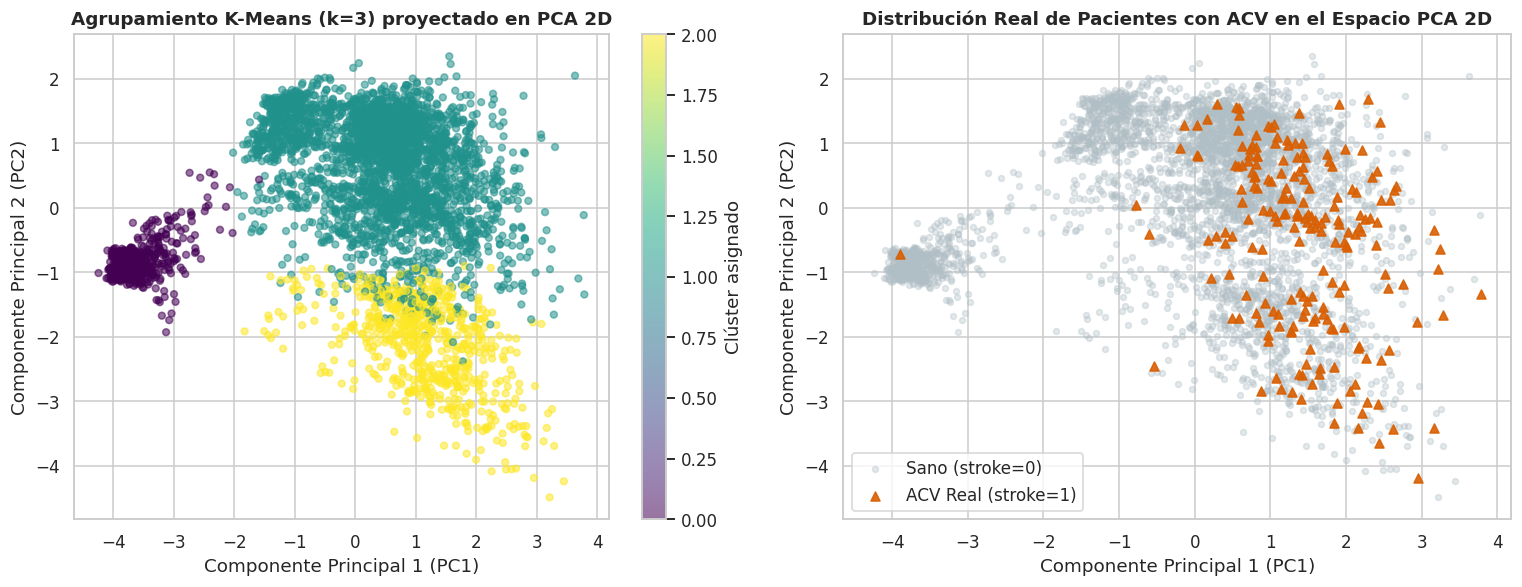

In [ ]:
# Ajustamos K-Means con k=3 (validado por codo/dendrograma para segmentar perfiles etarios/clínicos)
k_opt = 3
kmeans_final = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
clusters_train = kmeans_final.fit_predict(X_train_scaled)

# También ajustamos Jerárquico Aglomerativo con n_clusters=3 para comparar
agg_final = AgglomerativeClustering(n_clusters=k_opt, linkage='ward')
clusters_agg = agg_final.fit_predict(X_train_scaled)

# Reconstruir DataFrame con variables clínicas originales de Train para interpretar cada grupo
df_analisis_clusters = X_train.copy()
df_analisis_clusters['Cluster_KMeans'] = clusters_train
df_analisis_clusters['Stroke_Real'] = y_train.values

# Tabla de perfil clínico y tasa real de ACV por clúster
resumen_clusters = df_analisis_clusters.groupby('Cluster_KMeans').agg(
    Total_Pacientes=('Stroke_Real', 'count'),
    Casos_ACV_Reales=('Stroke_Real', 'sum'),
    Tasa_Incidencia_ACV_Pct=('Stroke_Real', lambda x: x.mean() * 100),
    Edad_Promedio=('age', 'mean'),
    Glucosa_Promedio=('avg_glucose_level', 'mean'),
    IMC_Mediano=('bmi', 'median'),
    Hipertension_Pct=('hypertension', lambda x: x.mean() * 100)
).round(2)

print("=== PERFIL CLÍNICO DE LOS CLÚSTERES (K-MEANS) CONTRA ETIQUETA REAL (STROKE) ===")
display(resumen_clusters)

# Visualización 2D: Clústeres descubiertos vs. Casos Reales de ACV
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

scatter1 = axes[0].scatter(
    X_train_pca2[:, 0], X_train_pca2[:, 1],
    c=clusters_train, cmap='viridis', alpha=0.55, s=20
)
axes[0].set_title(f'Agrupamiento K-Means (k={k_opt}) proyectado en PCA 2D', fontweight='bold')
axes[0].set_xlabel('Componente Principal 1 (PC1)')
axes[0].set_ylabel('Componente Principal 2 (PC2)')
plt.colorbar(scatter1, ax=axes[0], label='Clúster asignado')

# Subplot 2: Superposición de etiquetas reales de ACV
mask_sano = (y_train.values == 0)
mask_acv = (y_train.values == 1)

axes[1].scatter(X_train_pca2[mask_sano, 0], X_train_pca2[mask_sano, 1], c='#b0bec5', alpha=0.35, s=15, label='Sano (stroke=0)')
axes[1].scatter(X_train_pca2[mask_acv, 0], X_train_pca2[mask_acv, 1], c='#d95f02', alpha=0.90, s=35, marker='^', label='ACV Real (stroke=1)')
axes[1].set_title('Distribución Real de Pacientes con ACV en el Espacio PCA 2D', fontweight='bold')
axes[1].set_xlabel('Componente Principal 1 (PC1)')
axes[1].set_ylabel('Componente Principal 2 (PC2)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretación Clínica del Agrupamiento y Contraste con Etiquetas Reales (`stroke`)
* **Estratificación epidemiológica descubierta sin supervisión:** Al cruzar los $3$ clústeres hallados por K-Means sobre el conjunto de entrenamiento ($4,087$ pacientes) frente a la etiqueta real `stroke`, se comprueba que el algoritmo segmentó la población en tres perfiles médicos claramente diferenciados:
  * **Clúster 0 — Población Pediátrica / Juvenil ($572$ pacientes):** Edad promedio de **$7.13$ años**, glucosa normal ($94.51\text{ mg/dL}$), IMC mediano saludable ($19.00\text{ kg/m}^2$) y **$0.00\%$ de hipertensión**. Registra una incidencia casi nula de ACV (**$0.17\%$**, solo $1$ caso).
  * **Clúster 2 — Población Adulta Mayor de Alto Riesgo ($666$ pacientes):** Edad promedio de **$60.45$ años**, sobrepeso ($29.30\text{ kg/m}^2$), glucosa elevada ($111.17\text{ mg/dL}$) y la mayor tasa de hipertensión (**$16.97\%$**). Concentra una **tasa de incidencia de ACV del $8.26\%$** (**$48.6$ veces superior** al Clúster 0).
  * **Clúster 1 — Población Adulta Intermedia ($2,849$ pacientes):** Edad promedio de **$46.49$ años** e incidencia intermedia (**$5.02\%$**), concentrando el mayor volumen absoluto de eventos ($143$ de los $199$ casos positivos).
* **Conexión con el análisis de errores supervisado y limitaciones:** En la proyección 2D se observa que, aunque el Clúster 2 agrupa eficazmente el riesgo geriátrico-metabólico, los pacientes jóvenes que sufren ACV atípicos quedan inmersos dentro del Clúster 1 junto a adultos sanos. Esto confirma tanto las limitaciones del agrupamiento no supervisado frente a eventos de baja prevalencia ($4.87\%$) como la necesidad clínica de incorporar biomarcadores específicos de riesgo cerebrovascular juvenil en trabajos futuros.

---
# Conclusiones Finales del Proyecto y Conexión con el Curso

### 1. Síntesis Integral del Flujo de Ciencia de Datos
El desarrollo completo de este proyecto demuestra que la resolución efectiva de un problema de clasificación médica con desbalance severo ($95.13\%$ sanos vs. $4.87\%$ con ACV) depende de la articulación coherente de todas las etapas estudiadas en el curso:

* **Análisis Exploratorio de Datos (EDA) como fundamento del diseño:** La inspección estadística reveló la asimetría positiva de `avg_glucose_level` y `bmi`, justificando la imputación robusta mediante la mediana agrupada por rangos etarios y evitando la distorsión por valores atípicos. Asimismo, detectar la proporción $19:1$ entre clases permitió descartar el *Accuracy* como criterio de selección y establecer la **Sensibilidad (*Recall*)** y el **ROC-AUC** como métricas rectoras para minimizar los Falsos Negativos médicos.
* **Aprendizaje Supervisado y Selección de Arquitectura:** Se comprobó experimentalmente que, en datos tabulares clínicos desbalanceados, los métodos de ensamble regularizados superan a las redes neuronales densas. El **Random Forest Optimizado** (`n_estimators=200`, `max_depth=4`, `min_samples_split=2`, `class_weight='balanced'`) alcanzó un **Recall de $0.8594$ en validación cruzada** y **$0.8200$ en el conjunto de prueba (`X_test`)** con un **ROC-AUC de $0.8236$**. Por el contrario, el **Perceptrón Multicapa (MLP)** evidenció un sobreajuste hacia la clase mayoritaria ($90.26\%$ de *Accuracy*, pero apenas $11.06\% - 12.58\%$ de *Recall*), debido a que los gradientes de la clase sana dominan la función de pérdida de entropía cruzada estándar durante la retropropagación.
* **Aprendizaje No Supervisado y Reducción de Dimensionalidad:**
  * **Impacto de PCA:** Al comprimir las $15$ variables estandarizadas en $10$ componentes principales ($85\%$ de varianza explicada), el **Recall en *Test* cayó $12$ puntos porcentuales** (de $0.8200$ a $0.7000$) y el **ROC-AUC descendió de $0.8236$ a $0.7764$**. Dado que PCA es una proyección lineal no supervisada orientada a maximizar la varianza total de $X$ y no su correlación con `stroke`, diluye señales discriminantes de variables binarias poco frecuentes (`hypertension`, `heart_disease`) y rompe los cortes ortogonales directos sobre `age` y `avg_glucose_level`. Por ello, **se descarta PCA como etapa previa al clasificador final**.
  * **Segmentación mediante Clustering (K-Means $k=3$):** Validado mediante el método del codo, el coeficiente de silueta y el dendrograma jerárquico (enlace Ward), K-Means descubrió sin etiquetas tres perfiles epidemiológicos claros: un **clúster pediátrico/juvenil** ($\mu = 7.13$ años) con incidencia casi nula de ACV (**$0.17\%$**), un **clúster adulto intermedio** ($\mu = 46.49$ años, incidencia **$5.02\%$**) y un **clúster adulto mayor hipertenso** ($\mu = 60.45$ años, $16.97\%$ hipertensión) donde la incidencia alcanza el **$8.26\%$** (**$48.6$ veces superior** al grupo juvenil).

### 2. Fortalezas, Limitaciones y Trabajo Futuro
* **Principales fortalezas:** Diseño metodológico estricto sin fuga de datos (*data leakage*), partición estratificada consistente (`80/20` y `StratifiedKFold` de 5 pliegues) a lo largo de las tres entregas, optimización de hiperparámetros alineada al riesgo clínico y auditoría individual de errores sobre los casos reales de prueba.
* **Limitaciones identificadas:** La auditoría de la matriz de confusión en *Test* ($41$ Verdaderos Positivos vs. $9$ Falsos Negativos) y la proyección de clústeres demostraron que los pacientes jóvenes ($\mu = 39.3$ años) y normoglucémicos ($\mu = 82.6\text{ mg/dL}$) que sufren ACV atípicos quedan inmersos dentro de la población adulta general, pues el dataset carece de variables etiológicas específicas para ese grupo etario.
* **Líneas de mejora futura:**
  1. **Enriquecimiento de datos clínicos:** Incorporar presión arterial sistólica/diastólica cuantitativa, perfil lipídico (LDL/HDL), antecedentes familiares directos y marcadores de coagulación.
  2. **Funciones de pérdida sensibles al costo y ensambles de gradiente:** Evaluar **XGBoost / LightGBM** con `scale_pos_weight` y entrenar redes neuronales con **Focal Loss** junto con ajuste fino del umbral probabilístico ($T < 0.5$) para elevar el *Recall* por encima del $90\%$.
  3. **Explicabilidad Clínica (XAI):** Integrar valores **SHAP** (*SHapley Additive exPlanations*) para ofrecer al personal médico una interpretación transparente de los factores que impulsan cada predicción individual.